# Example 5.1: Trajectory Analysis and Initial Error
**Chapter 5 · Formulation of the Synthesis Problem**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Statement
Given the four-bar mechanism with lengths **a=60, b=90, c=70, d=85 mm**, calculate the coupler curve for 360 crank positions θ₂ ∈ [0°, 360°] and compare it with the desired elliptical trajectory defined by:

- Center: (45, 25) mm
- Half axles: 22 × 18 mm (20 points)

Report the **Hausdorff error**, the **mean point-to-curve distance**, and the number of valid positions. Plot both curves with the error vectors.

**Objective:** establish the base evaluation function E(x) that the GA (Genetic Algorithm) will minimize during trajectory synthesis.

In [4]:
from numpy import *
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'serif', 'font.size': 12})

# ── Function of the coupling curve─────────────────────────────────────────
def fourbar_coupler(a, b, c, d, th2, p=40., delta=pi/6):
    K1=d/a; K2=d/c; K3=(a**2-b**2+c**2+d**2)/(2*a*c)
    A=cos(th2)-K1-K2*cos(th2)+K3; B=-2*sin(th2)
    C=K1-(K2+1)*cos(th2)+K3
    disc=B**2-4*A*C
    th4=where(disc>=0, 2*arctan2(-B-sqrt(maximum(disc,0)),2*A), nan)
    K4=d/b; K5=(c**2-d**2-a**2-b**2)/(2*a*b)
    A2=cos(th2)-K1+K4*cos(th2)+K5; B2=-2*sin(th2)
    C2=K1+(K4-1)*cos(th2)+K5
    disc2=B2**2-4*A2*C2
    th3=where(disc>=0, 2*arctan2(-B2-sqrt(maximum(disc2,0)),2*A2), nan)
    return a*cos(th2)+p*cos(th3+delta), a*sin(th2)+p*sin(th3+delta)

# ── Desired trajectory (ellipse)───────────────────────────────────────────
t = linspace(0, 2*pi, 20)
Pd_x = 45 + 22*cos(t)
Pd_y = 25 + 18*sin(t)

# ── Coupler curve───────────────────────────────────────────────────────
a, b, c, d = 60., 90., 70., 85.
th2 = linspace(0, 2*pi, 360)
Cx, Cy = fourbar_coupler(a, b, c, d, th2)
valido = isfinite(Cx)

# ── Hausdorff error calculation─────────────────────────────────────────
Cx2 = Cx[valido]; Cy2 = Cy[valido]
D = sqrt((Cx2[:,None]-Pd_x[None,:])**2 + (Cy2[:,None]-Pd_y[None,:])**2)
d1 = D.min(0).max(); d2 = D.min(1).max()
hausdorff  = float(maximum(d1, d2))
dist_media = mean([D[:,i].min() for i in range(len(Pd_x))])

print(f"Initial Hausdorff error: {hausdorff:.2f} mm")
print(f"Mean distance P→C:       {dist_media:.2f} mm")
print(f"Valid coupler points:    {valido.sum()} / {len(th2)}")



Initial Hausdorff error: 62.17 mm
Mean distance P→C:       12.80 mm
Valid coupler points:    360 / 360


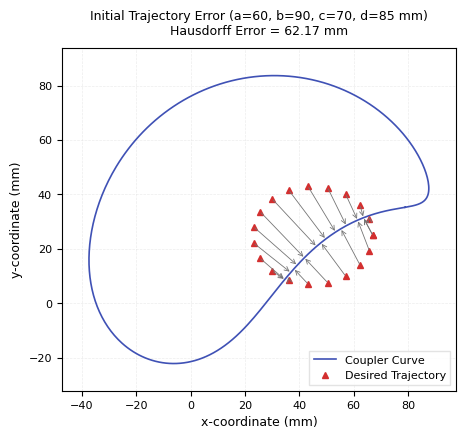

In [5]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt

# ── Automated Filename System ──────────────────────────────────────────
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_5_1_initial_trajectory_error"
except Exception:
    notebook_name = "Figure_5_1_initial_trajectory_error"

# ── Springer Technical/Design Configurations ─────────────────────────────
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 8,
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8
})

# ── Figure Initialization (Compact single-column layout) ────────────────
fig, ax = plt.subplots(figsize=(4.7, 4.5))

# Plot coupler curve and desired trajectory with high-quality styling
ax.plot(Cx[valido], Cy[valido], color='#3F51B5', lw=1.2, linestyle='-', label='Coupler Curve')
ax.plot(Pd_x, Pd_y, color='#D32F2F', marker='^', markersize=4.5, linestyle='', label='Desired Trajectory')

# Vector error lines (with adjusted arrow sizes to avoid clutter)
for i in range(len(Pd_x)):
    j_near = D[:, i].argmin()
    ax.annotate('',
                xy=(Cx2[j_near], Cy2[j_near]),
                xytext=(Pd_x[i], Pd_y[i]),
                arrowprops=dict(arrowstyle='->', color='#757575', lw=0.6, shrinkA=1, shrinkB=1))

# Set labels in academic English
ax.set_xlabel('x-coordinate (mm)')
ax.set_ylabel('y-coordinate (mm)')
ax.set_title(f'Initial Trajectory Error (a={a:.0f}, b={b:.0f}, c={c:.0f}, d={d:.0f} mm)\nHausdorff Error = {hausdorff:.2f} mm', pad=10)

# Elegant layout limits and grid
ax.grid(True, linestyle='--', color='#E0E0E0', alpha=0.6, lw=0.5)
ax.set_aspect('equal')

# Expand axes limits to ensure clean margins and no overlapping with boundary text
ax.set_xlim(Cx[valido].min() - 10, Cx[valido].max() + 10)
ax.set_ylim(Cy[valido].min() - 10, Cy[valido].max() + 10)

# Legend position without overlapping data
ax.legend(loc='lower right', frameon=True, fancybox=False, edgecolor='#E0E0E0', framealpha=0.9)

plt.tight_layout()

# ── Double Mandatory Export ─────────────────────────────────────────────
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()